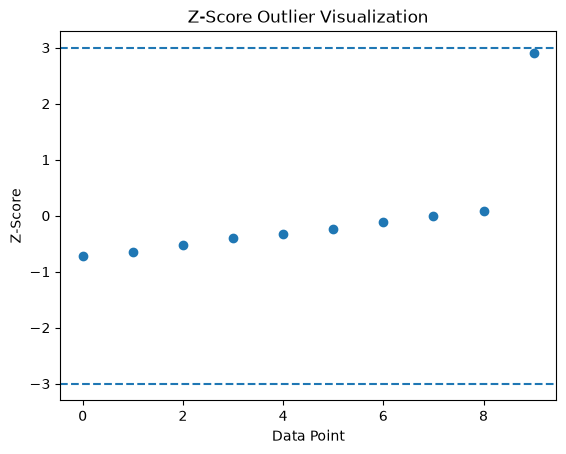

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import zscore

data = np.array([10, 12, 15, 18, 20, 22, 25, 28, 30, 100])

z_scores = zscore(data)

plt.scatter(range(len(data)), z_scores)

plt.axhline(3, linestyle="--")
plt.axhline(-3, linestyle="--")

plt.xlabel("Data Point")
plt.ylabel("Z-Score")
plt.title("Z-Score Outlier Visualization")

plt.show()

In [2]:
%pip install seaborn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python3.14t.exe -m pip install --upgrade pip


In [3]:
import seaborn as sns

In [4]:

df = sns.load_dataset("tips")


In [5]:
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [6]:
df.shape

(244, 7)

{'whiskers': [<matplotlib.lines.Line2D at 0x5322c44ac90>,
 'caps': [<matplotlib.lines.Line2D at 0x5322c44b290>,
 'boxes': [<matplotlib.lines.Line2D at 0x5322c44ae10>],
 'medians': [<matplotlib.lines.Line2D at 0x5322c44af90>],
 'fliers': [<matplotlib.lines.Line2D at 0x5322c44b710>],
 'means': []}

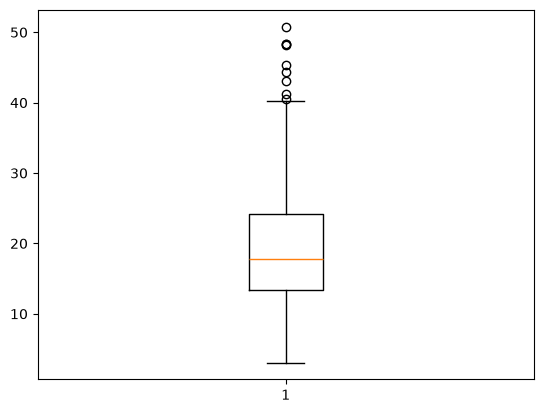

In [7]:
plt.boxplot(df['total_bill'])

In [8]:
q1= df['total_bill'].quantile(0.25)
q3= df['total_bill'].quantile(0.75)
iqr=q3-q1
print('iqr----', iqr)

iqr---- 10.779999999999998


In [9]:
q1= df['total_bill'].quantile(0.25)
q3= df['total_bill'].quantile(0.75)
iqr=q3-q1

lower= q1-1.5*iqr

upper= q3+1.5*iqr

df[(df['total_bill']<upper) & (df['total_bill']>lower)]

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


In [10]:
q1= df['total_bill'].quantile(0.25)
q3= df['total_bill'].quantile(0.75)
iqr=q3-q1
print('iqr--------',iqr)
lower= q1-1.5*iqr
print('lower------',lower)
upper= q3+1.5*iqr
print('upper------',upper)

iqr-------- 10.779999999999998
lower------ -2.8224999999999945
upper------ 40.29749999999999


{'whiskers': [<matplotlib.lines.Line2D at 0x5322c446310>,
 'caps': [<matplotlib.lines.Line2D at 0x5322c446610>,
 'boxes': [<matplotlib.lines.Line2D at 0x5322c447510>],
 'medians': [<matplotlib.lines.Line2D at 0x5322c445a10>],
 'fliers': [<matplotlib.lines.Line2D at 0x5322c444c90>],
 'means': []}

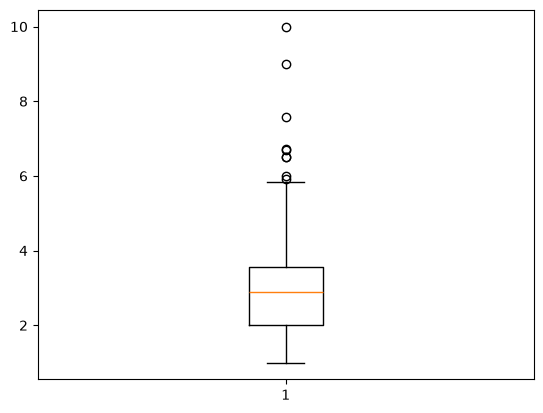

In [11]:
df['tip']=df['tip'].clip(upper=upper)
plt.boxplot(df['tip'])

In [12]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder,LabelEncoder
from sklearn.compose import ColumnTransformer

In [13]:
df.columns

Index(['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size'], dtype='str')

In [14]:
num_fea=['total_bill']
ohe_fea=['sex','smoker']
min_max=['tip']


In [20]:
import pandas as pd

In [21]:
from sklearn.preprocessing._data import MinMaxScaler
tranformer=ColumnTransformer(
transformers=[('num',StandardScaler(),num_fea),
('min_max',MinMaxScaler(),min_max),
('cat',OneHotEncoder(drop='first'),ohe_fea)],
remainder='passthrough'
)

In [22]:
tranformer.fit_transform(df)

array([[-0.3147113050904943, 0.0011111111111111183, 0.0, ..., 'Sun',
        'Dinner', 2],
       [-1.0632353132988692, 0.07333333333333333, 1.0, ..., 'Sun',
        'Dinner', 3],
       [0.13777989987156145, 0.27777777777777773, 1.0, ..., 'Sun',
        'Dinner', 3],
       ...,
       [0.3246295019205694, 0.1111111111111111, 1.0, ..., 'Sat',
        'Dinner', 2],
       [-0.2212865040659901, 0.08333333333333331, 1.0, ..., 'Sat',
        'Dinner', 2],
       [-0.11322890288102155, 0.2222222222222222, 0.0, ..., 'Thur',
        'Dinner', 2]], shape=(244, 7), dtype=object)

In [24]:
pd.DataFrame(tranformer.fit_transform(df),columns=tranformer.get_feature_names_out())

,num__total_bill,min_max__tip,cat__sex_Male,cat__smoker_Yes,remainder__day,remainder__time,remainder__size
0,-0.314711,0.001111,0.0,0.0,Sun,Dinner,2
1,-1.063235,0.073333,1.0,0.0,Sun,Dinner,3
2,0.13778,0.277778,1.0,0.0,Sun,Dinner,3
3,0.438315,0.256667,1.0,0.0,Sun,Dinner,2
4,0.540745,0.29,0.0,0.0,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,1.040511,0.546667,1.0,0.0,Sat,Dinner,3
240,0.832275,0.111111,0.0,1.0,Sat,Dinner,2
241,0.32463,0.111111,1.0,1.0,Sat,Dinner,2
242,-0.221287,0.083333,1.0,0.0,Sat,Dinner,2
